In [2]:
import os
from PIL import Image

data_path = "/app/data/raw/Data"
good_extensions = [".jpg", ".jpeg", ".png"]

In [3]:
valid_images = {}
bad_images = []

for class_name in os.listdir(data_path):
    class_path = os.path.join(data_path, class_name)
    valid_images[class_name] = []

    for file_name in os.listdir(class_path):
        file_path = os.path.join(class_path, file_name)
        extension = os.path.splitext(file_name)[1].lower()

        if extension not in good_extensions:
            bad_images.append(file_path)
            continue

        try:
            img = Image.open(file_path)
            img.verify()
            valid_images[class_name].append(file_path)
        except:
            bad_images.append(file_path)

In [4]:
for class_name in valid_images:
    print(class_name, ":", len(valid_images[class_name]))

print("Bad files:", len(bad_images))
print(bad_images)

glioma : 1621
meningioma : 1645
notumor : 2000
pituitary : 1757
Bad files: 0
[]


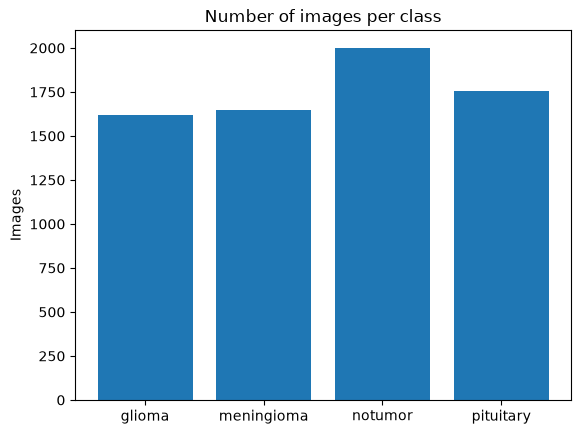

In [5]:
import matplotlib.pyplot as plt

names = list(valid_images.keys())
counts = []
for name in names:
    counts.append(len(valid_images[name]))

plt.bar(names, counts)
plt.title("Number of images per class")
plt.ylabel("Images")
plt.show()

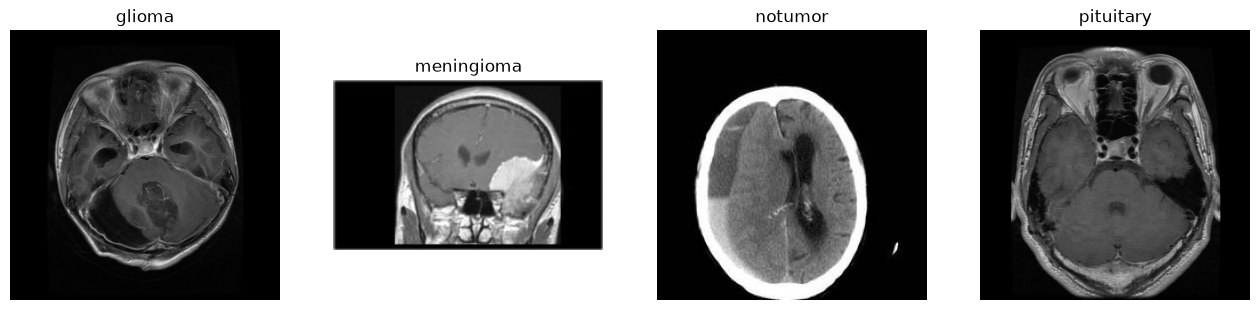

<Figure size 640x480 with 0 Axes>

In [8]:
plt.figure(figsize=(16, 4))

for i, name in enumerate(names):
    img = Image.open(valid_images[name][0])
    plt.subplot(1, 4, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(name)
    plt.axis("off")

plt.show()
plt.savefig("/app/reports/class_counts.png")

In [9]:
print(names)
print(counts)

['glioma', 'meningioma', 'notumor', 'pituitary']
[1621, 1645, 2000, 1757]


In [10]:
from sklearn.model_selection import train_test_split


all_files = []
all_labels = []

for class_name in valid_images:
    for file_path in valid_images[class_name] :
        all_files.append(file_path)
        all_labels.append(class_name)

train_files, temp_files , train_labels, temp_labels = train_test_split(
    all_files,all_labels,
    test_size=0.3,random_state=42,stratify=all_labels,
)


val_files,test_files,val_labels,test_labels = train_test_split(
    temp_files,temp_labels,
    test_size=0.5,stratify=temp_labels,random_state=42
)

In [11]:
splits = {"train": {}, "val": {}, "test": {}}
for split_name in splits:
    for class_name in valid_images:
        splits[split_name][class_name] = []

for file_path, label in zip(train_files, train_labels):
    splits["train"][label].append(file_path)
for file_path, label in zip(val_files, val_labels):
    splits["val"][label].append(file_path)
for file_path, label in zip(test_files, test_labels):
    splits["test"][label].append(file_path)

In [17]:
import shutil

out_path = "/app/data/processed/classification"

for split_name in splits:
    for class_name in splits[split_name]:
        folder = os.path.join(out_path, split_name, class_name)
        os.makedirs(folder, exist_ok=True)

        for file_path in splits[split_name][class_name]:
            shutil.copy(file_path, folder)

In [18]:
for split_name in splits:
    total = 0
    print(split_name)
    for class_name in splits[split_name]:
        count = len(splits[split_name][class_name])
        total = total + count
        print("  ", class_name, ":", count)
    print("   total:", total)

train
   glioma : 1135
   meningioma : 1151
   notumor : 1400
   pituitary : 1230
   total: 4916
val
   glioma : 243
   meningioma : 247
   notumor : 300
   pituitary : 263
   total: 1053
test
   glioma : 243
   meningioma : 247
   notumor : 300
   pituitary : 264
   total: 1054


Filter---------------------------------------------------Purpose

ImageFilter.BLUR-----------------------------------------Makes the image blurry.

ImageFilter.SHARPEN--------------------------------------Sharpens details.

ImageFilter.EDGE_ENHANCE---------------------------------Enhances edges.

ImageFilter.CONTOUR--------------------------------------Highlights outlines and contours.

ImageFilter.FIND_EDGES-----------------------------------Detects edges in the image.

ImageFilter.GaussianBlur(radius=2)-----------------------Applies adjustable Gaussian blur.

Function---------------------------------------------------Purpose

ImageOps.grayscale(image)---------------------------------------------------Converts to grayscale.

ImageOps.invert(image)---------------------------------------------------Inverts colors.

ImageOps.contain(image, size)---------------------------------------------------Fits inside a size while preserving proportions.

ImageOps.fit(image, size)---------------------------------------------------Resizes and crops to fill the exact size.

ImageOps.autocontrast(image)---------------------------------------------------Adjusts contrast based on pixel values.

ImageOps.mirror(image)---------------------------------------------------Flips the image horizontally.

ImageOps.flip(image)---------------------------------------------------Flips the image vertically.


In [23]:
import numpy as np
from PIL import Image,ImageFilter, ImageOps
import random

random.seed(42)
np.random.seed(42)

def blur(img):
    return img.filter(ImageFilter.GaussianBlur(radius=2))


def flip(img):
    return ImageOps.mirror(img)

def add_noise(img):
    arr = np.array(img).astype("float32")
    noise = np.random.normal(0,15,arr.shape)
    arr = np.clip(arr + noise,0,255).astype("uint8")
    return Image.fromarray(arr)

augment_functions = [blur, flip, add_noise]


In [25]:
import random
train_path = "/app/data/processed/classification/train"
target = 0
for class_name in splits["train"]:
    if len(splits["train"][class_name]) > target:
        target = len(splits["train"][class_name])
        
        
for class_name in splits["train"]:
    originals = splits["train"][class_name]
    missing = target - len(originals)
    folder = os.path.join(train_path, class_name)
    
    for i in range(missing):
        file_path = random.choice(originals)
        func = random.choice(augment_functions)
        
        img = Image.open(file_path)
        new_img = func(img)
        new_img.save(os.path.join(folder,"aug_" + str(i) + ".jpg"))
    
    print(class_name, ": added", missing, "images")

glioma : added 265 images
meningioma : added 249 images
notumor : added 0 images
pituitary : added 170 images


In [26]:
for class_name in os.listdir(train_path):
    folder = os.path.join(train_path, class_name)
    print(class_name, ":", len(os.listdir(folder)))

glioma : 1400
meningioma : 1400
notumor : 1400
pituitary : 1400
